### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

MAX_VALUE = 255
NUM_LEVELS = 256
OTSU_AUTO = 0
MIN_OBJECT_AREA = 250
EDGE_TOL = 2  # px tolerance when matching edge pixels
SEED = 123

COLORS = {
    "clean": "tab:blue",
    "noisy": "tab:orange",
    "none": "tab:gray",
    "gaussian": "tab:green",
    "median": "tab:red",
    "bilateral": "tab:purple",
    "equalized": "tab:brown",
    "threshold": "black",
    "single": "tab:blue",
    "crowd": "tab:orange",
    "expected": "tab:gray",
}

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

In [2]:
coins = cv2.imread('data/coins_gray.bmp', cv2.IMREAD_GRAYSCALE)
coins_noise = cv2.imread('data/coins_gray_noisy.bmp', cv2.IMREAD_GRAYSCALE)

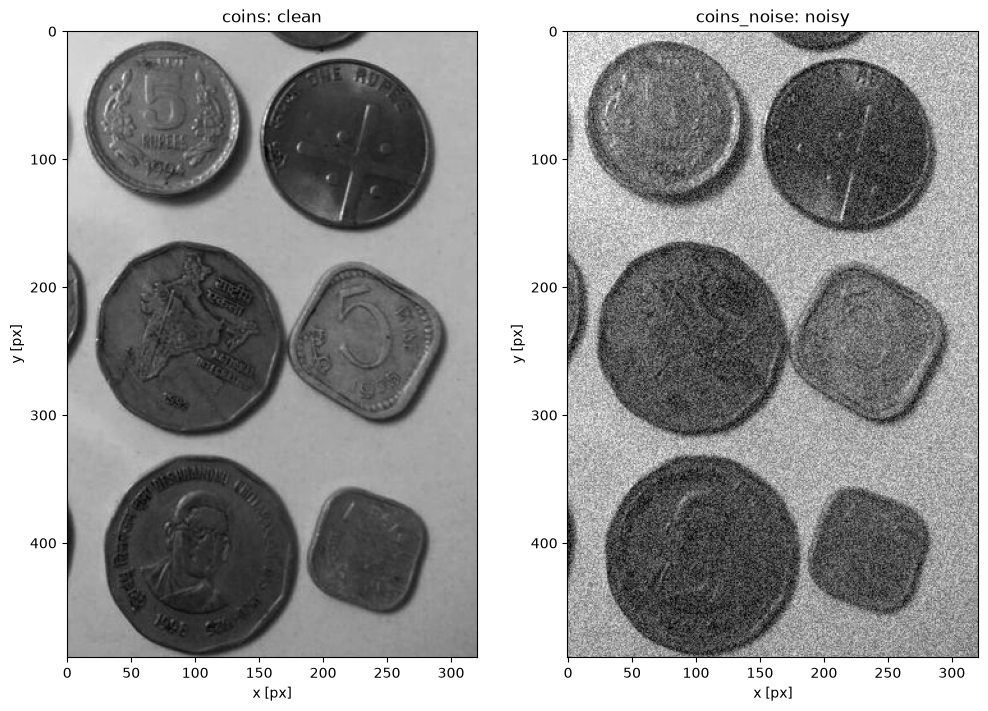

In [3]:
def show_image(ax, img, title, cmap="gray"):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("x [px]")
    ax.set_ylabel("y [px]")


fig, axes = plt.subplots(1, 2, figsize=(10, 7), constrained_layout=True)
show_image(axes[0], coins, "coins: clean")
show_image(axes[1], coins_noise, "coins_noise: noisy")
plt.show()

Rozwiązanie:

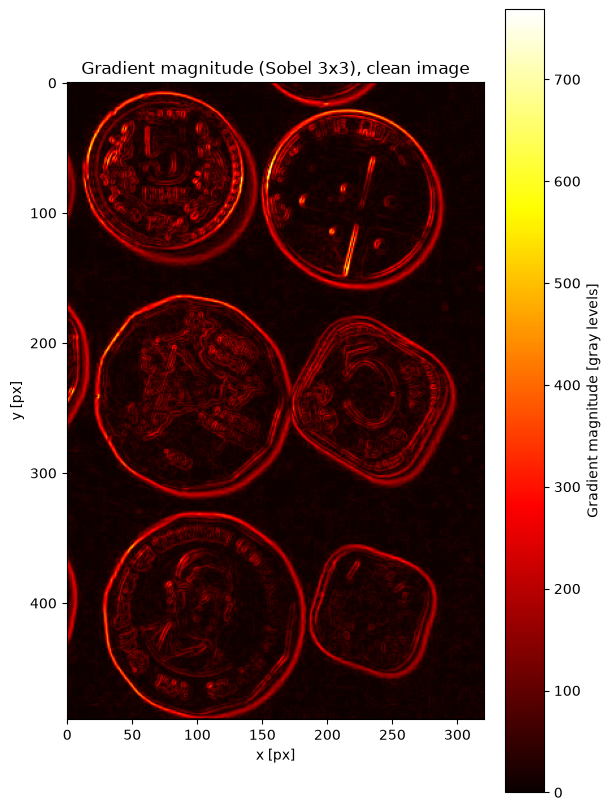

In [4]:
def gradient_magnitude(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    return cv2.magnitude(gx, gy)


grad = gradient_magnitude(coins)

fig, ax = plt.subplots(figsize=(6, 8), constrained_layout=True)
im = ax.imshow(grad, cmap="hot")
ax.set_title("Gradient magnitude (Sobel 3x3), clean image")
ax.set_xlabel("x [px]")
ax.set_ylabel("y [px]")
fig.colorbar(im, ax=ax, label="Gradient magnitude [gray levels]")
plt.show()

Where is the gradient near zero? Share of pixels below a fraction of the maximum, and the magnitude histogram.

magnitude < 2% of max: 45.1% of pixels
magnitude < 5% of max: 69.5% of pixels
magnitude < 10% of max: 83.1% of pixels


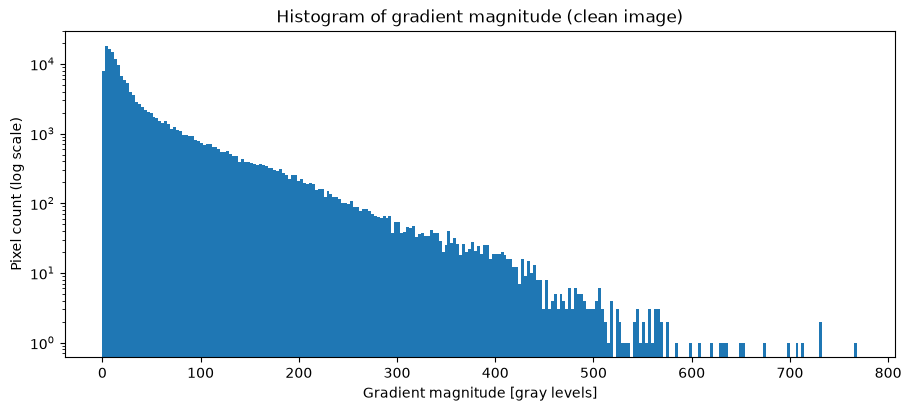

In [5]:
ZERO_FRACTIONS = (0.02, 0.05, 0.10)
for f in ZERO_FRACTIONS:
    share = (grad < f * grad.max()).mean()
    print(f"magnitude < {f:.0%} of max: {share:.1%} of pixels")

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.hist(grad.ravel(), bins=NUM_LEVELS, color=COLORS["clean"])
ax.set_yscale("log")
ax.set_title("Histogram of gradient magnitude (clean image)")
ax.set_xlabel("Gradient magnitude [gray levels]")
ax.set_ylabel("Pixel count (log scale)")
plt.show()

Can objects be detected from the magnitude alone? Otsu on the magnitude, then count outer contours.

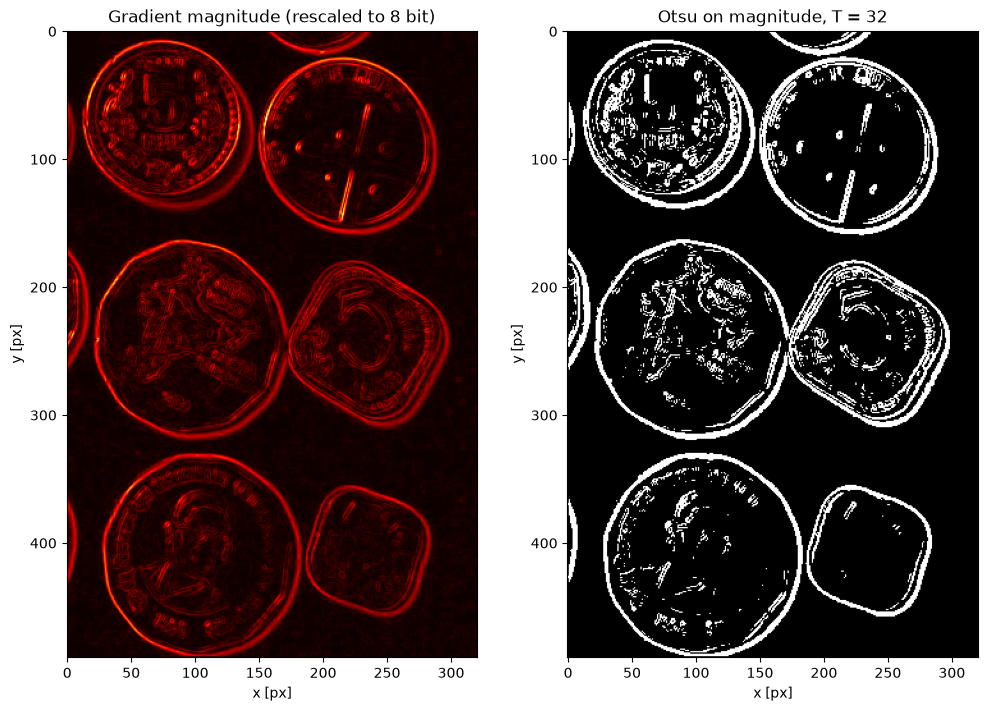

outer contours with area >= 250px: 7 (expected 9)


In [6]:
def count_contours(mask):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return sum(cv2.contourArea(c) >= MIN_OBJECT_AREA for c in contours)


grad_u8 = cv2.convertScaleAbs(grad, alpha=MAX_VALUE / grad.max())
t_grad, mask_grad = cv2.threshold(grad_u8, OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
EXPECTED_OBJECTS = 9  # 6 coins + 3 border fragments, same count as in lab 1

fig, axes = plt.subplots(1, 2, figsize=(10, 7), constrained_layout=True)
show_image(axes[0], grad_u8, "Gradient magnitude (rescaled to 8 bit)", cmap="hot")
show_image(axes[1], mask_grad, f"Otsu on magnitude, T = {t_grad:.0f}")
plt.show()
print(f"outer contours with area >= {MIN_OBJECT_AREA}px: {count_contours(mask_grad)} (expected {EXPECTED_OBJECTS})")

Conclusions 1:
- Gradients are near zero in the flat background and coin interiors: 45% / 70% / 83% of pixels are below 2% / 5% / 10% of the maximum.
- Rims give the strongest response, relief inside the coins gives weaker, fragmented responses.
- Otsu on the magnitude gives rings and inner clutter, not filled objects: 7 contours instead of 9. The magnitude alone is not enough to separate objects; it needs edge thinning/linking (Canny) and a closing step.

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

Rozwiązanie:

Noise reduction candidates, defined once. Each parameter is varied in the experiments below.

In [7]:
GAUSS_SMALL, GAUSS_LARGE = 5, 9
MEDIAN_KERNEL = 5
BILATERAL_D, BILATERAL_SIGMA = 9, 75
LOW_RATIO = 0.5  # low threshold = LOW_RATIO * high threshold

DENOISERS = {
    "none": lambda img: img,
    f"gaussian {GAUSS_SMALL}x{GAUSS_SMALL}": lambda img: cv2.GaussianBlur(img, (GAUSS_SMALL, GAUSS_SMALL), 0),
    f"gaussian {GAUSS_LARGE}x{GAUSS_LARGE}": lambda img: cv2.GaussianBlur(img, (GAUSS_LARGE, GAUSS_LARGE), 0),
    f"median {MEDIAN_KERNEL}": lambda img: cv2.medianBlur(img, MEDIAN_KERNEL),
    "bilateral": lambda img: cv2.bilateralFilter(img, BILATERAL_D, BILATERAL_SIGMA, BILATERAL_SIGMA),
}
DENOISER_COLORS = dict(zip(DENOISERS, [COLORS["none"], "tab:green", "darkgreen", COLORS["median"], COLORS["bilateral"]]))


def canny(img, high, low_ratio=LOW_RATIO):
    return cv2.Canny(img, int(high * low_ratio), int(high))

Validation: there is no ground-truth edge map, so the noisy image is compared with the Canny edges of the clean image (the noise is the independent perturbation).
An edge pixel counts as matched if a reference edge lies within `EDGE_TOL` px. Reported: precision, recall, F1.

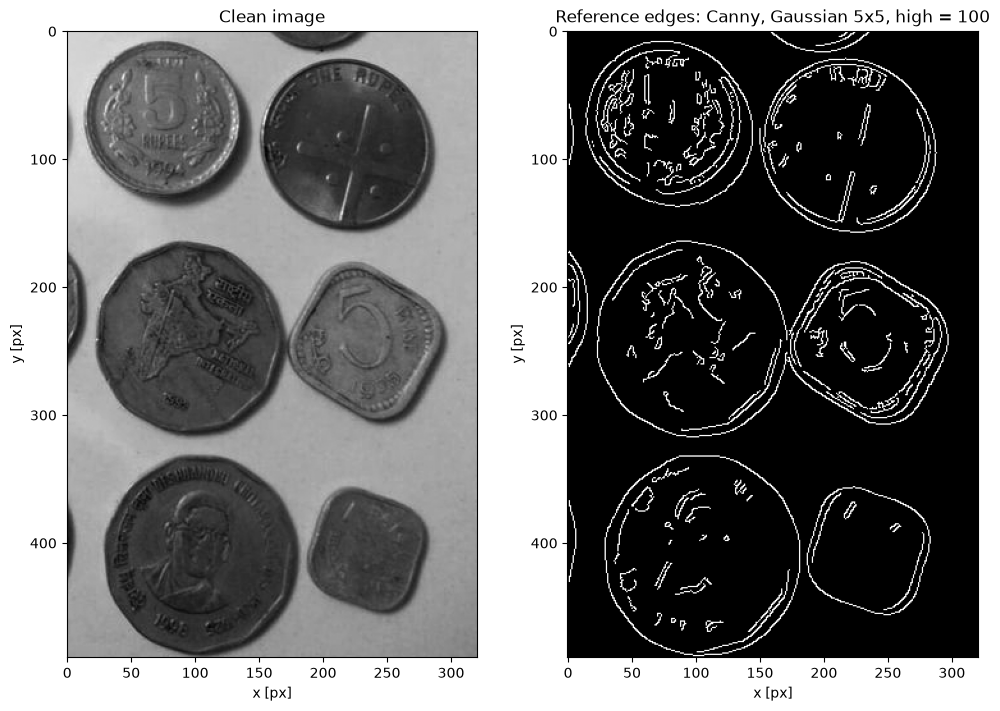

In [8]:
def edge_scores(edges, ref):
    dist_to_ref = cv2.distanceTransform(cv2.bitwise_not(ref), cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    dist_to_edges = cv2.distanceTransform(cv2.bitwise_not(edges), cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    if not edges.any():
        return 0.0, 0.0, 0.0
    precision = (dist_to_ref[edges > 0] <= EDGE_TOL).mean()
    recall = (dist_to_edges[ref > 0] <= EDGE_TOL).mean()
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1


REF_HIGH = 100
edges_ref = canny(cv2.GaussianBlur(coins, (GAUSS_SMALL, GAUSS_SMALL), 0), REF_HIGH)

fig, axes = plt.subplots(1, 2, figsize=(10, 7), constrained_layout=True)
show_image(axes[0], coins, "Clean image")
show_image(axes[1], edges_ref, f"Reference edges: Canny, Gaussian {GAUSS_SMALL}x{GAUSS_SMALL}, high = {REF_HIGH}")
plt.show()

Effect of the thresholds: F1 against the high threshold, one curve per noise reduction method.

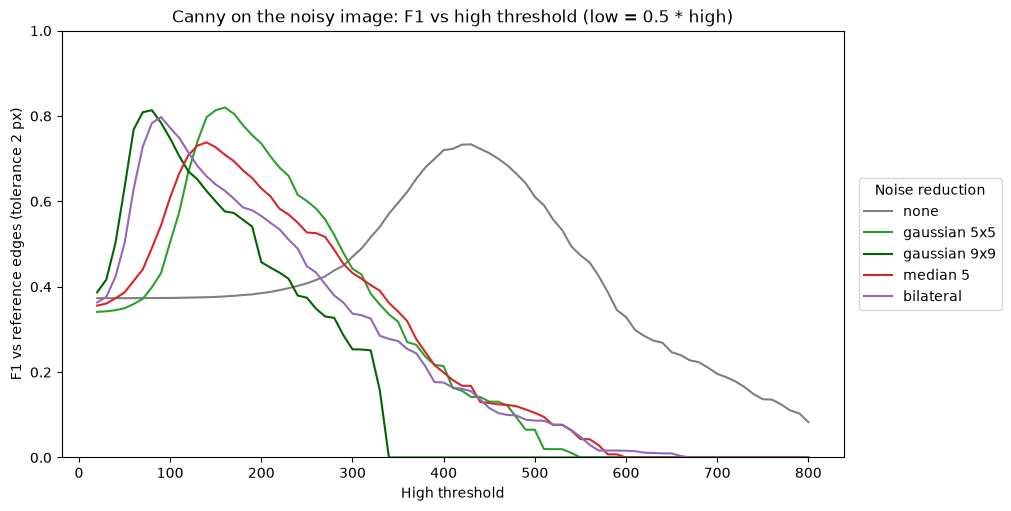

none            best high = 430  F1 = 0.734
gaussian 5x5    best high = 160  F1 = 0.820
gaussian 9x9    best high =  80  F1 = 0.814
median 5        best high = 140  F1 = 0.738
bilateral       best high =  90  F1 = 0.798


In [9]:
HIGH_SWEEP = np.arange(20, 801, 10)
sweep_f1 = {}
for name, fn in DENOISERS.items():
    smoothed = fn(coins_noise)
    sweep_f1[name] = [edge_scores(canny(smoothed, h), edges_ref)[2] for h in HIGH_SWEEP]

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for name, vals in sweep_f1.items():
    ax.plot(HIGH_SWEEP, vals, color=DENOISER_COLORS[name], label=name)
ax.set_title(f"Canny on the noisy image: F1 vs high threshold (low = {LOW_RATIO} * high)")
ax.set_xlabel("High threshold")
ax.set_ylabel(f"F1 vs reference edges (tolerance {EDGE_TOL} px)")
ax.set_ylim(0, 1)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Noise reduction")
plt.show()

best = {n: (HIGH_SWEEP[int(np.argmax(v))], max(v)) for n, v in sweep_f1.items()}
for n, (h, f) in best.items():
    print(f"{n:15s} best high = {h:3d}  F1 = {f:.3f}")

Effect of the low/high ratio for the best method.

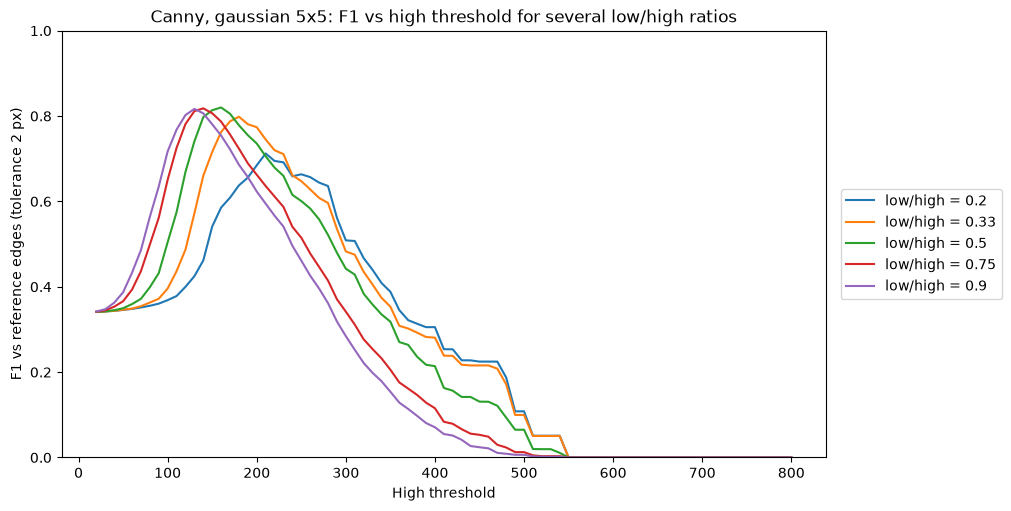

ratio 0.2: best high = 210, F1 = 0.712
ratio 0.33: best high = 180, F1 = 0.798
ratio 0.5: best high = 160, F1 = 0.820
ratio 0.75: best high = 140, F1 = 0.818
ratio 0.9: best high = 130, F1 = 0.817


In [10]:
RATIOS = (0.2, 0.33, 0.5, 0.75, 0.9)
best_name = max(best, key=lambda n: best[n][1])
smoothed_best = DENOISERS[best_name](coins_noise)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ratio_best = {}
for r in RATIOS:
    vals = [edge_scores(canny(smoothed_best, h, r), edges_ref)[2] for h in HIGH_SWEEP]
    ratio_best[r] = (HIGH_SWEEP[int(np.argmax(vals))], max(vals))
    ax.plot(HIGH_SWEEP, vals, label=f"low/high = {r}")
ax.set_title(f"Canny, {best_name}: F1 vs high threshold for several low/high ratios")
ax.set_xlabel("High threshold")
ax.set_ylabel(f"F1 vs reference edges (tolerance {EDGE_TOL} px)")
ax.set_ylim(0, 1)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()
for r, (h, f) in ratio_best.items():
    print(f"ratio {r}: best high = {h}, F1 = {f:.3f}")

Visual comparison at the best high threshold of each method.

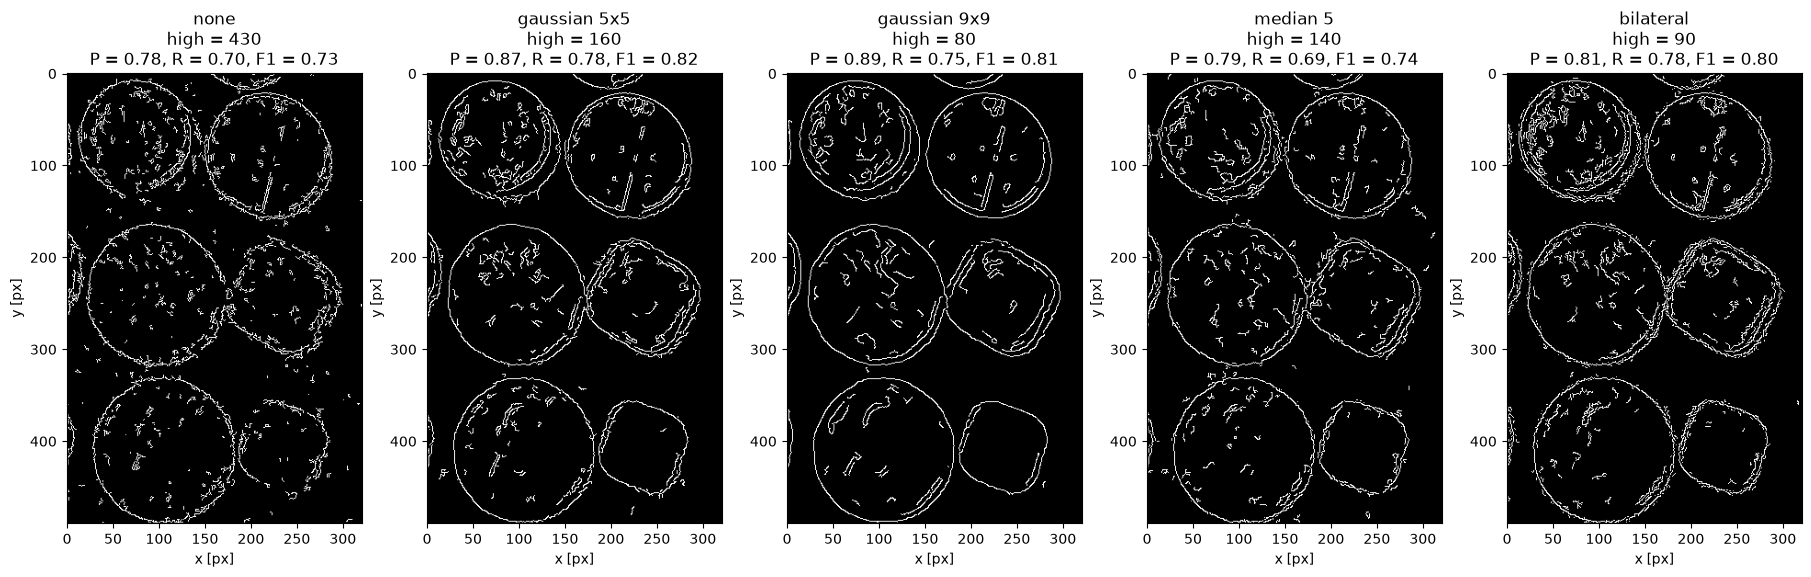

In [11]:
fig, axes = plt.subplots(1, len(DENOISERS), figsize=(18, 6), constrained_layout=True)
for ax, (name, fn) in zip(axes, DENOISERS.items()):
    h = best[name][0]
    p, r, f = edge_scores(canny(fn(coins_noise), h), edges_ref)
    show_image(ax, canny(fn(coins_noise), h), f"{name}\nhigh = {h}\nP = {p:.2f}, R = {r:.2f}, F1 = {f:.2f}")
plt.show()

Conclusions 2:
- Without smoothing the best high threshold is 430 (F1 0.73): the threshold must be high to suppress noise, which also removes weak true edges.
- With smoothing the best threshold drops to 80-160: Gaussian 5x5 F1 0.82, Gaussian 9x9 0.81, bilateral 0.80, median 0.74.
- Low/high ratio 0.5-0.9 gives the same best F1 (about 0.82); 0.2 is worse (0.71).
- Caveat: the reference is Canny on the clean image blurred with Gaussian 5x5, so the Gaussian 5x5 result is partly favoured by construction. The ranking of smoothing versus no smoothing is the safe conclusion.

---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

Rozwiązanie:

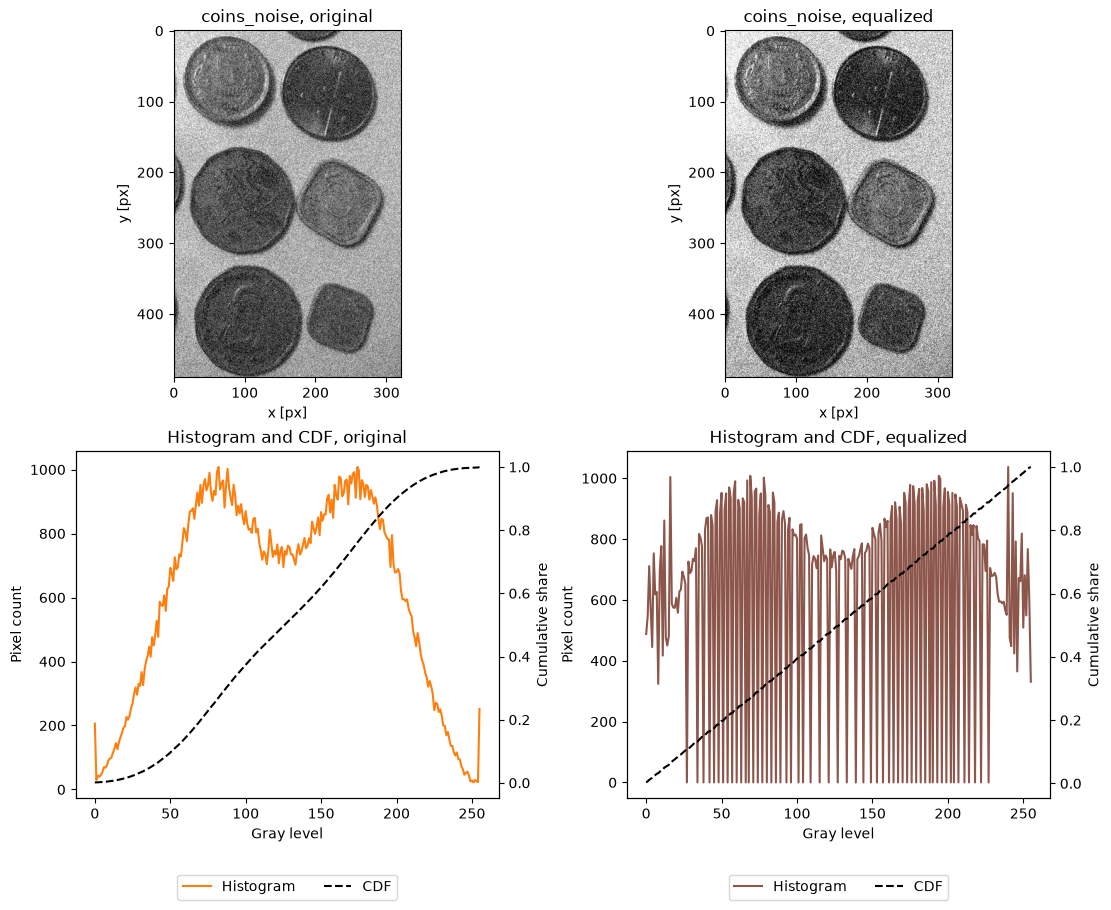

In [12]:
coins_noise_eq = cv2.equalizeHist(coins_noise)
coins_eq = cv2.equalizeHist(coins)


def hist_cdf(img):
    hist = np.bincount(img.ravel(), minlength=NUM_LEVELS)
    return hist, np.cumsum(hist) / img.size


fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
for col, (img, label, color) in enumerate([(coins_noise, "original", COLORS["noisy"]), (coins_noise_eq, "equalized", COLORS["equalized"])]):
    show_image(axes[0, col], img, f"coins_noise, {label}")
    hist, cdf = hist_cdf(img)
    ax = axes[1, col]
    ax.plot(hist, color=color, label="Histogram")
    ax.set_title(f"Histogram and CDF, {label}")
    ax.set_xlabel("Gray level")
    ax.set_ylabel("Pixel count")
    ax2 = ax.twinx()
    ax2.plot(cdf, color="black", linestyle="--", label="CDF")
    ax2.set_ylabel("Cumulative share")
    ax.legend(handles=ax.get_lines() + ax2.get_lines(), loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.show()

Edge detection on the equalized image, same protocol as in task 2.
The reference is Canny of the equalized clean image, so both sides undergo the same gray-level mapping.

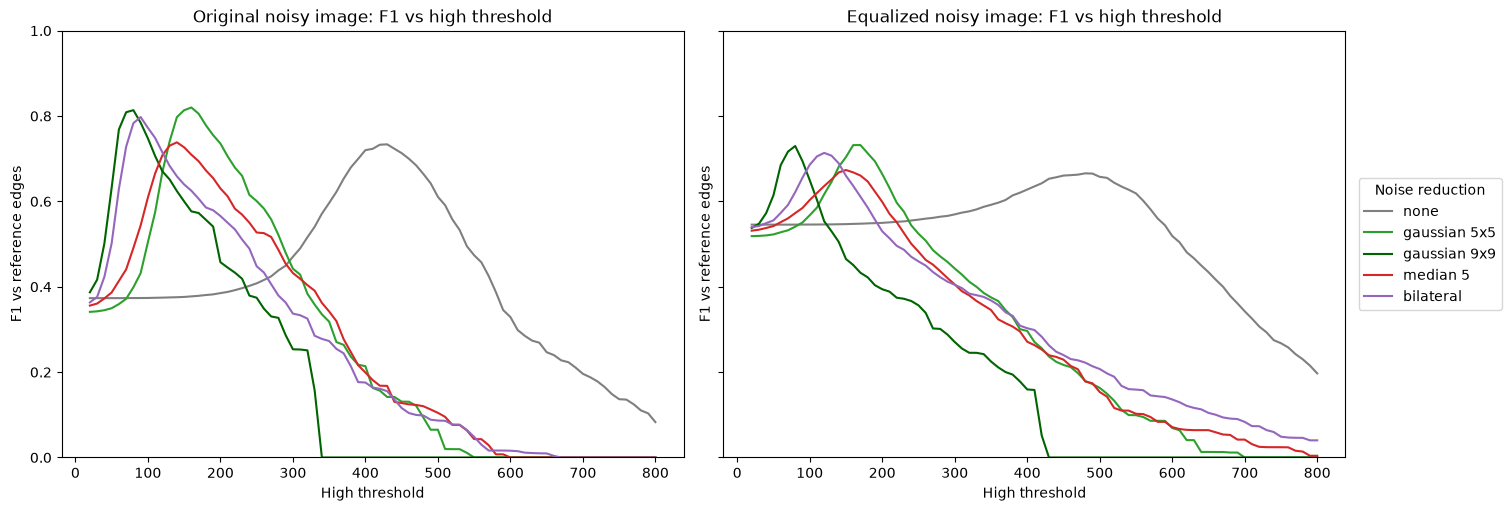

none            original: high = 430 F1 = 0.734 | equalized: high = 480 F1 = 0.666
gaussian 5x5    original: high = 160 F1 = 0.820 | equalized: high = 170 F1 = 0.732
gaussian 9x9    original: high =  80 F1 = 0.814 | equalized: high =  80 F1 = 0.730
median 5        original: high = 140 F1 = 0.738 | equalized: high = 150 F1 = 0.674
bilateral       original: high =  90 F1 = 0.798 | equalized: high = 120 F1 = 0.714


In [13]:
edges_ref_eq = canny(cv2.GaussianBlur(coins_eq, (GAUSS_SMALL, GAUSS_SMALL), 0), REF_HIGH)

sweep_eq = {}
for name, fn in DENOISERS.items():
    smoothed = fn(coins_noise_eq)
    sweep_eq[name] = [edge_scores(canny(smoothed, h), edges_ref_eq)[2] for h in HIGH_SWEEP]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True, sharey=True)
for ax, sweep, title in [(axes[0], sweep_f1, "Original noisy image"), (axes[1], sweep_eq, "Equalized noisy image")]:
    for name, vals in sweep.items():
        ax.plot(HIGH_SWEEP, vals, color=DENOISER_COLORS[name], label=name)
    ax.set_title(f"{title}: F1 vs high threshold")
    ax.set_xlabel("High threshold")
    ax.set_ylabel("F1 vs reference edges")
    ax.set_ylim(0, 1)
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Noise reduction")
plt.show()

best_eq = {n: (HIGH_SWEEP[int(np.argmax(v))], max(v)) for n, v in sweep_eq.items()}
for n in DENOISERS:
    print(f"{n:15s} original: high = {best[n][0]:3d} F1 = {best[n][1]:.3f} | equalized: high = {best_eq[n][0]:3d} F1 = {best_eq[n][1]:.3f}")

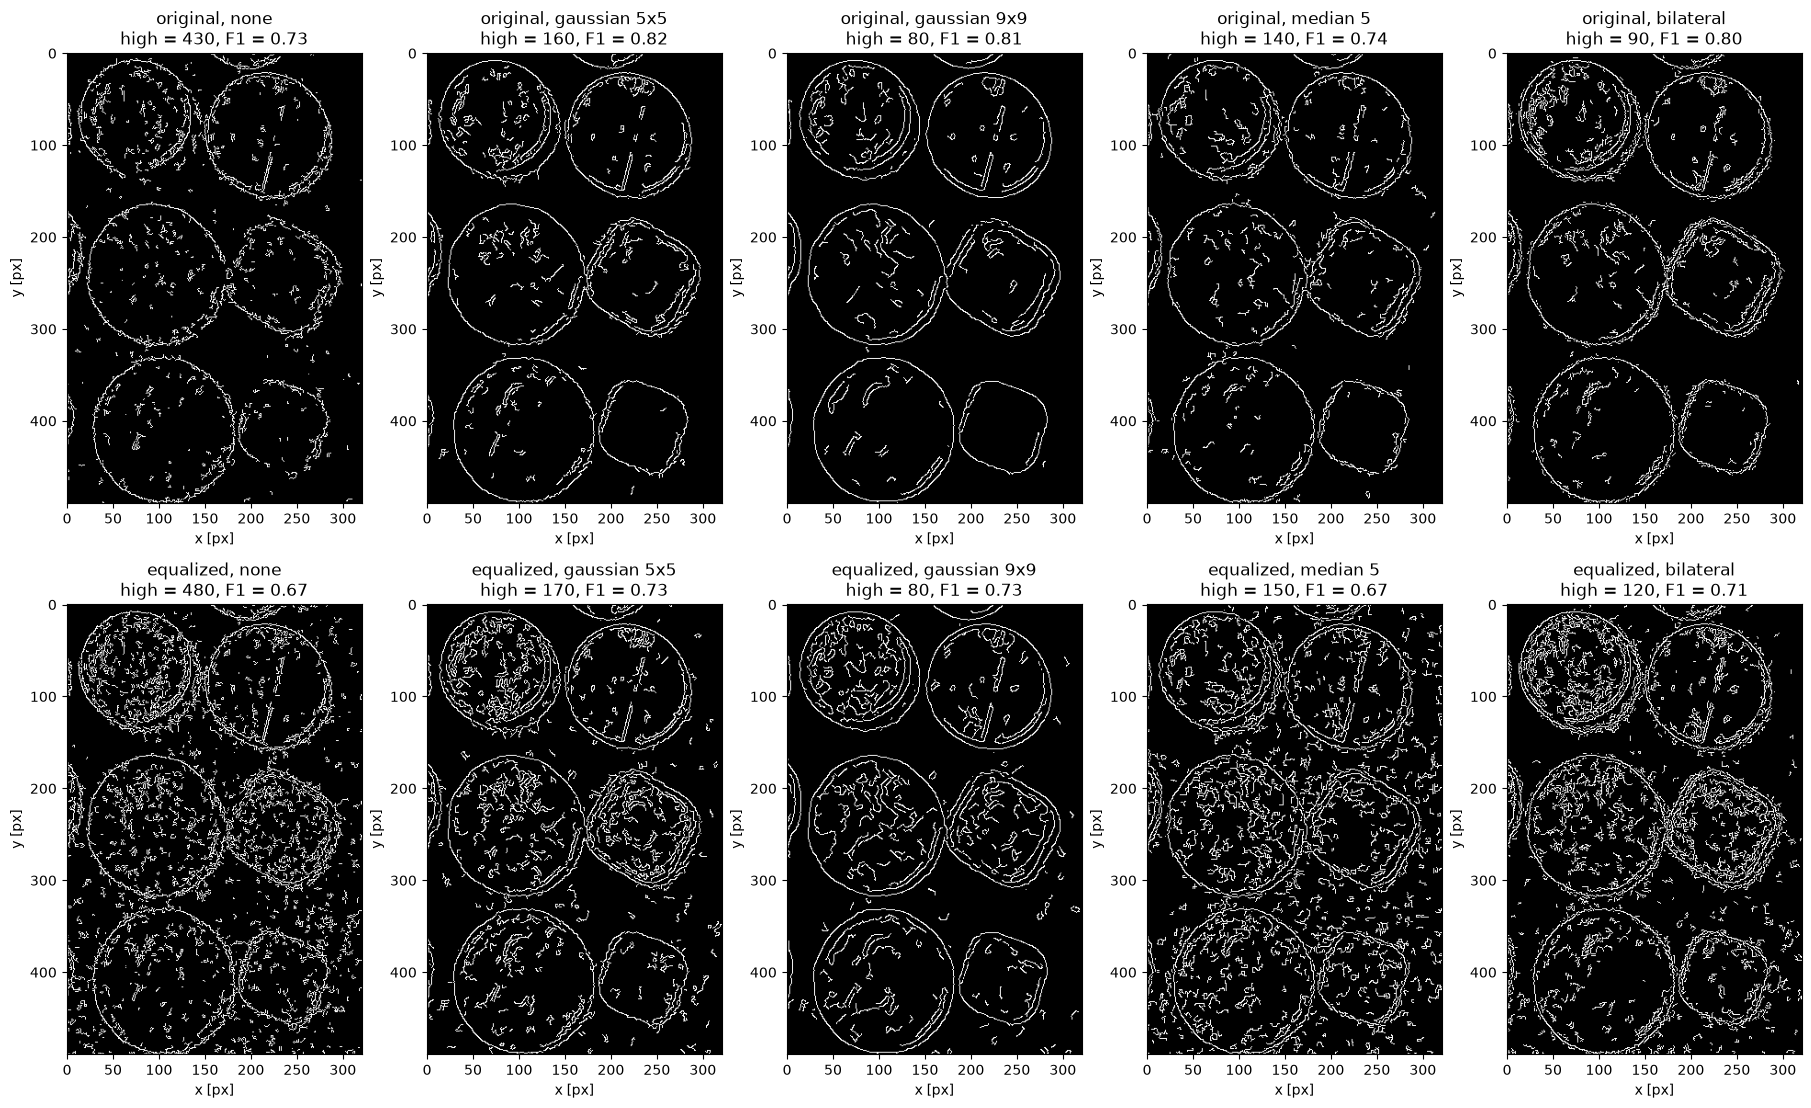

In [14]:
fig, axes = plt.subplots(2, len(DENOISERS), figsize=(18, 11), constrained_layout=True)
for col, (name, fn) in enumerate(DENOISERS.items()):
    for row, (img, ref, b, label) in enumerate([(coins_noise, edges_ref, best, "original"), (coins_noise_eq, edges_ref_eq, best_eq, "equalized")]):
        h = b[name][0]
        edges = canny(fn(img), h)
        p, r, f = edge_scores(edges, ref)
        show_image(axes[row, col], edges, f"{label}, {name}\nhigh = {h}, F1 = {f:.2f}")
plt.show()

Same high threshold on both images (the original's best for the median filter), to isolate the effect of equalization.

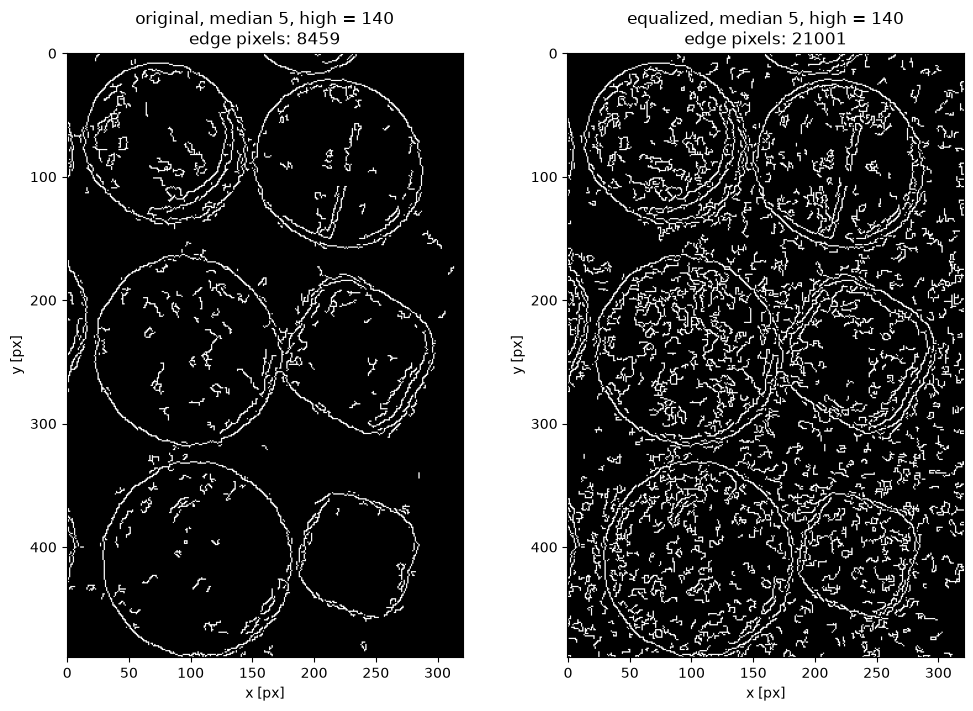

In [15]:
SAME_HIGH = best[f"median {MEDIAN_KERNEL}"][0]
fig, axes = plt.subplots(1, 2, figsize=(10, 7), constrained_layout=True)
for ax, img, label in [(axes[0], coins_noise, "original"), (axes[1], coins_noise_eq, "equalized")]:
    edges = canny(cv2.medianBlur(img, MEDIAN_KERNEL), SAME_HIGH)
    show_image(ax, edges, f"{label}, median {MEDIAN_KERNEL}, high = {SAME_HIGH}\nedge pixels: {int((edges > 0).sum())}")
plt.show()

Conclusions 3:
- Equalization lowers the best F1 for every method (none 0.73 to 0.67, Gaussian 5x5 0.82 to 0.73, median 0.74 to 0.67, bilateral 0.80 to 0.71).
- At the same thresholds the equalized image gives 21001 edge pixels against 8459: equalization stretches contrast and amplifies the noise together with the edges.
- The coin edges do not get stronger relative to the noise, so equalization does not help edge detection here.

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

In [16]:
albatross_single = cv2.imread('data/albatross_single.png', cv2.IMREAD_GRAYSCALE)
albatross_crowd = cv2.imread('data/albatross_crowd.png', cv2.IMREAD_GRAYSCALE)

Rozwiązanie:

Independent reference annotations drawn by hand (not produced by any threshold):
a polygon around the bright part of the single bird (head, neck, breast), and the head position of each visible bird in the crowd.
Very small distant birds were not annotated.

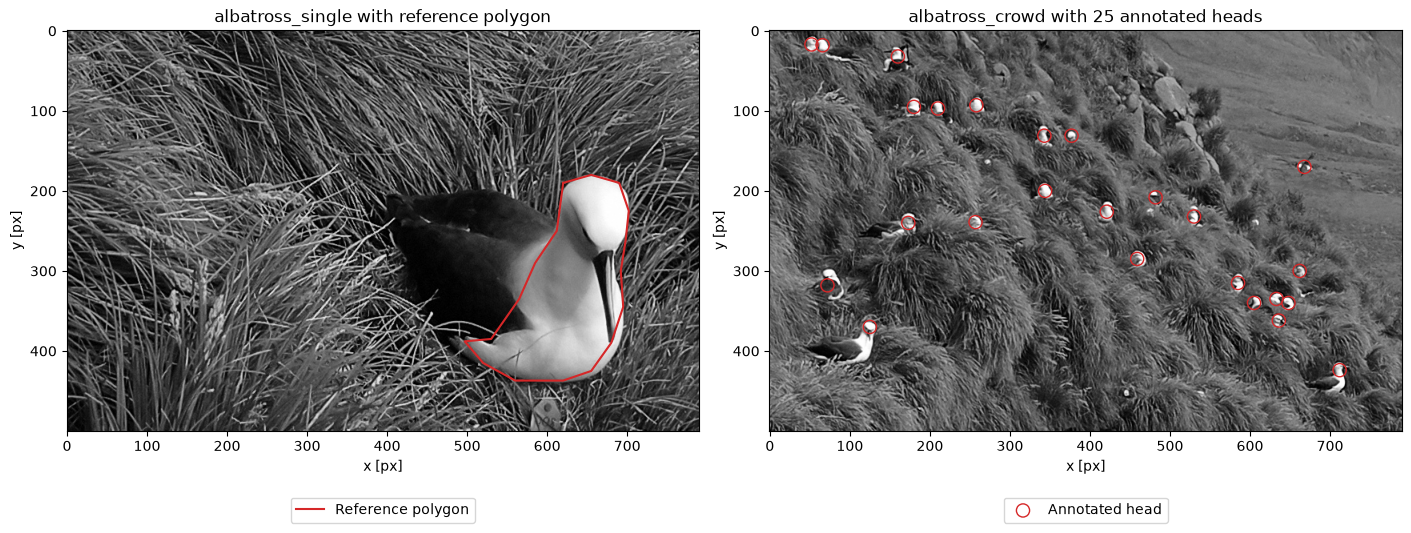

bird share of the single image (reference): 7.40%


In [17]:
SINGLE_POLYGON = np.array([
    (620, 190), (655, 180), (690, 190), (702, 225), (698, 262), (692, 300), (695, 345), (680, 390),
    (655, 425), (620, 437), (560, 437), (520, 415), (497, 388), (530, 385), (565, 335), (585, 290), (612, 250),
])
CROWD_POINTS = np.array([
    (52, 17), (66, 18), (160, 32), (180, 95), (210, 97), (258, 93), (343, 131), (377, 131), (344, 200),
    (421, 226), (530, 232), (482, 208), (257, 239), (173, 240), (459, 285), (585, 315), (605, 340),
    (633, 335), (648, 340), (636, 362), (662, 300), (72, 318), (125, 370), (712, 424), (668, 170),
])
POINT_TOL = 8  # px: a detection within this distance of an annotated head counts as a hit
MIN_BIRD_AREA = 15

ref_single = np.zeros_like(albatross_single)
cv2.fillPoly(ref_single, [SINGLE_POLYGON], MAX_VALUE)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
show_image(axes[0], albatross_single, "albatross_single with reference polygon")
axes[0].plot(*np.vstack([SINGLE_POLYGON, SINGLE_POLYGON[:1]]).T, color="tab:red", label="Reference polygon")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
show_image(axes[1], albatross_crowd, f"albatross_crowd with {len(CROWD_POINTS)} annotated heads")
axes[1].scatter(*CROWD_POINTS.T, s=90, facecolors="none", edgecolors="tab:red", label="Annotated head")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()
print(f"bird share of the single image (reference): {(ref_single > 0).mean():.2%}")

Histogram matching via cumulative distributions: for each gray level `g`, pick the target level `j` whose target CDF is closest above the source CDF value at `g`.

In [18]:
LEVELS = np.arange(NUM_LEVELS)


def cdf_of(img):
    return np.cumsum(np.bincount(img.ravel(), minlength=NUM_LEVELS)) / img.size


def match_histogram(img, target_pdf):
    target_cdf = np.cumsum(target_pdf / target_pdf.sum())
    lut = np.searchsorted(target_cdf, cdf_of(img)).clip(0, MAX_VALUE).astype(np.uint8)
    return cv2.LUT(img, lut)


def gaussian_pdf(mu, sigma):
    pdf = np.exp(-0.5 * ((LEVELS - mu) / sigma) ** 2)
    return pdf / pdf.sum()


def bimodal_pdf(bright_share, mu_dark=60, mu_bright=200, sigma=25):
    return (1 - bright_share) * gaussian_pdf(mu_dark, sigma) + bright_share * gaussian_pdf(mu_bright, sigma)


def otsu_mask(img):
    t, mask = cv2.threshold(img, OTSU_AUTO, MAX_VALUE, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return t, mask

Metrics: IoU against the polygon for the single bird; recall, precision and F1 of detected components against annotated heads for the crowd.

In [19]:
def iou(mask, ref):
    inter = np.logical_and(mask > 0, ref > 0).sum()
    union = np.logical_or(mask > 0, ref > 0).sum()
    return inter / union


def crowd_scores(mask):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= MIN_BIRD_AREA]
    kept_mask = np.isin(labels, keep)
    near = cv2.dilate(kept_mask.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * POINT_TOL + 1, 2 * POINT_TOL + 1)))
    hits = sum(bool(near[y, x]) for x, y in CROWD_POINTS)
    useful = len({labels[y + dy, x + dx] for x, y in CROWD_POINTS for dy in range(-POINT_TOL, POINT_TOL + 1) for dx in range(-POINT_TOL, POINT_TOL + 1)
                  if 0 <= y + dy < labels.shape[0] and 0 <= x + dx < labels.shape[1] and labels[y + dy, x + dx] in keep})
    recall = hits / len(CROWD_POINTS)
    precision = min(useful, len(keep)) / len(keep) if keep else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return recall, precision, f1, len(keep)


t0_s, mask0_s = otsu_mask(albatross_single)
t0_c, mask0_c = otsu_mask(albatross_crowd)
print(f"baseline Otsu, single: T = {t0_s:.0f}, IoU = {iou(mask0_s, ref_single):.3f}")
r, p, f, n = crowd_scores(mask0_c)
print(f"baseline Otsu, crowd:  T = {t0_c:.0f}, recall = {r:.2f}, precision = {p:.2f}, F1 = {f:.2f}, components = {n}")

baseline Otsu, single: T = 91, IoU = 0.156
baseline Otsu, crowd:  T = 85, recall = 1.00, precision = 0.02, F1 = 0.03, components = 249


Target shapes compared at one setting each. The bright-mode share of the bimodal target is set to the true bird share of the single image.

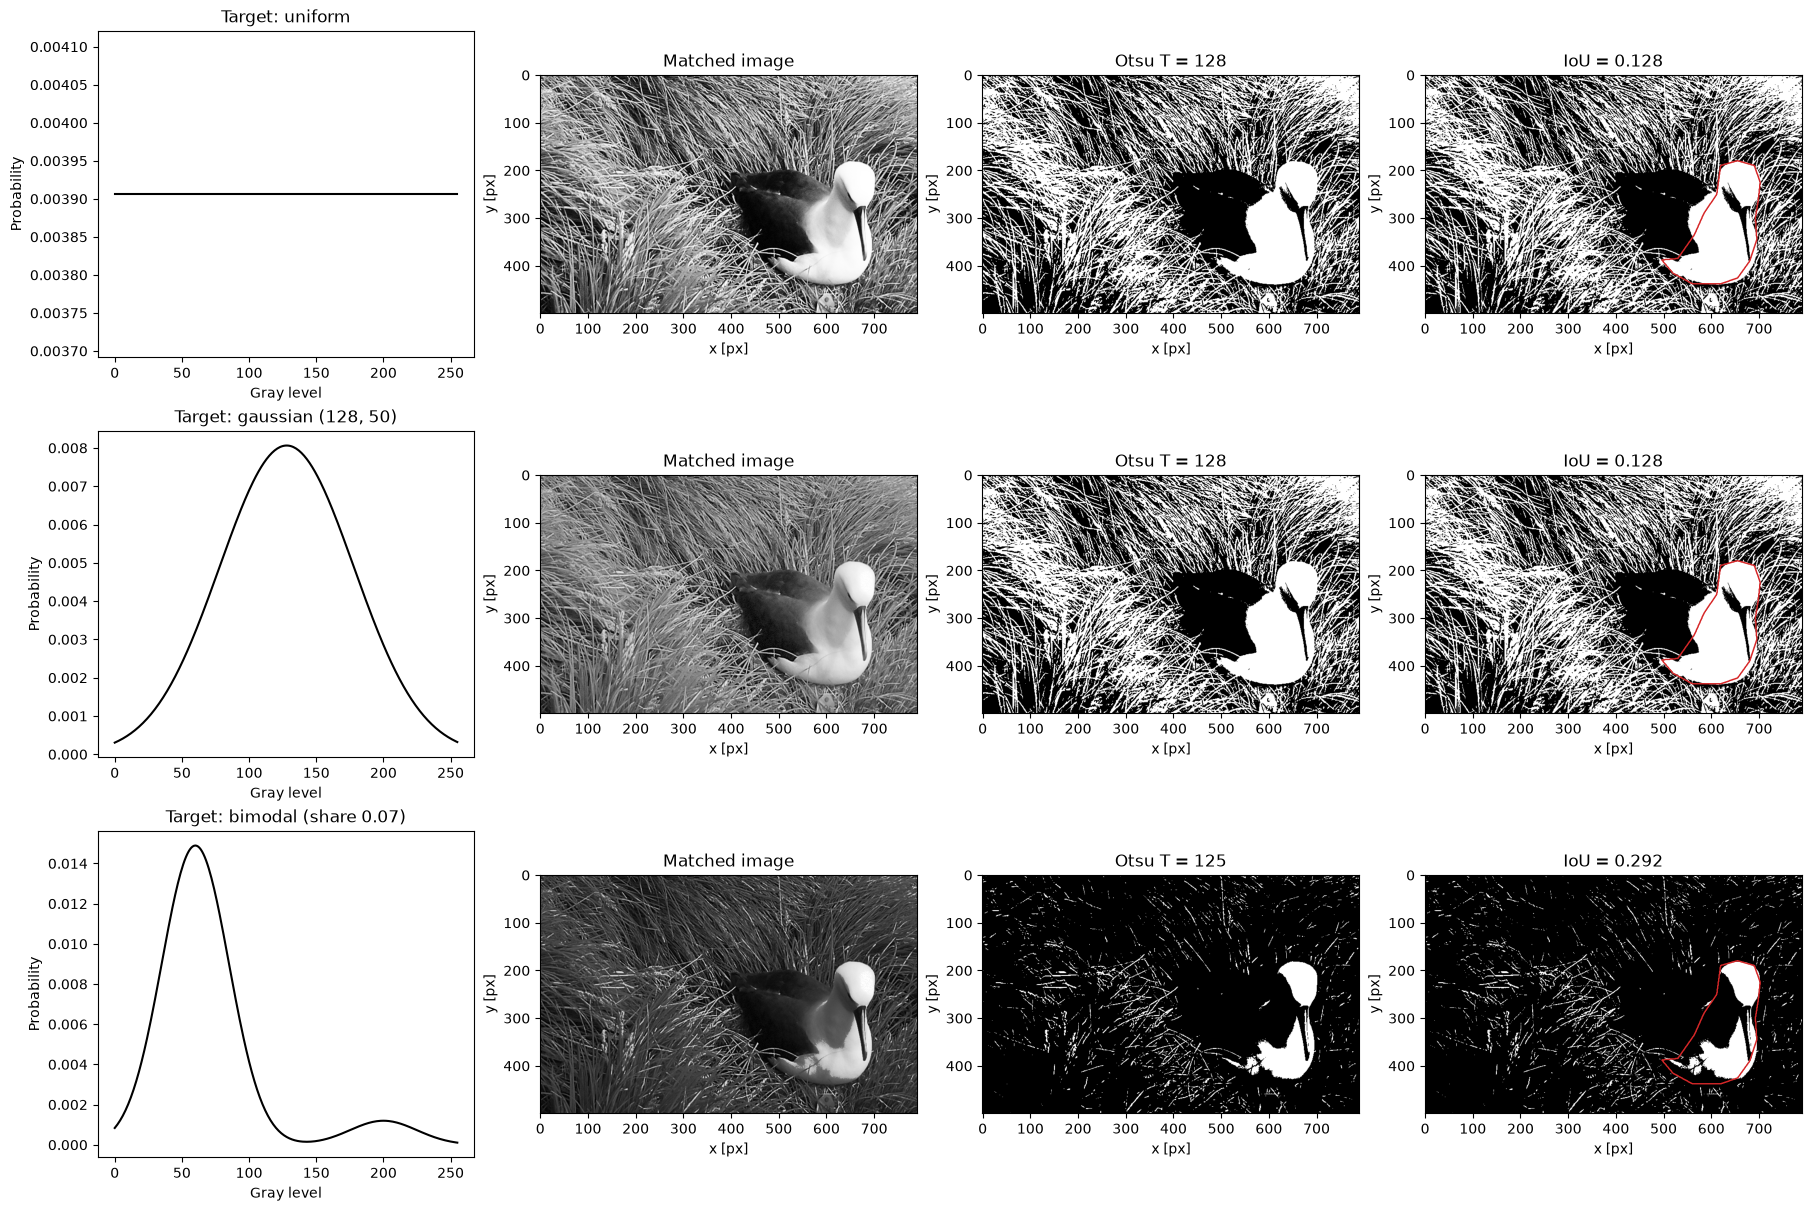

In [20]:
BIRD_SHARE = float((ref_single > 0).mean())
TARGETS = {
    "uniform": np.ones(NUM_LEVELS) / NUM_LEVELS,
    "gaussian (128, 50)": gaussian_pdf(128, 50),
    f"bimodal (share {BIRD_SHARE:.2f})": bimodal_pdf(BIRD_SHARE),
}

fig, axes = plt.subplots(len(TARGETS), 4, figsize=(18, 12), constrained_layout=True)
for row, (name, pdf) in enumerate(TARGETS.items()):
    out = match_histogram(albatross_single, pdf)
    t, mask = otsu_mask(out)
    axes[row, 0].plot(LEVELS, pdf, color=COLORS["threshold"])
    axes[row, 0].set_title(f"Target: {name}")
    axes[row, 0].set_xlabel("Gray level")
    axes[row, 0].set_ylabel("Probability")
    show_image(axes[row, 1], out, "Matched image")
    show_image(axes[row, 2], mask, f"Otsu T = {t:.0f}")
    show_image(axes[row, 3], mask, f"IoU = {iou(mask, ref_single):.3f}")
    axes[row, 3].contour(ref_single, levels=[MAX_VALUE / 2], colors="tab:red", linewidths=1)
plt.show()

Parameter study on the single bird: share of the bright mode, distance between modes, and mode width.

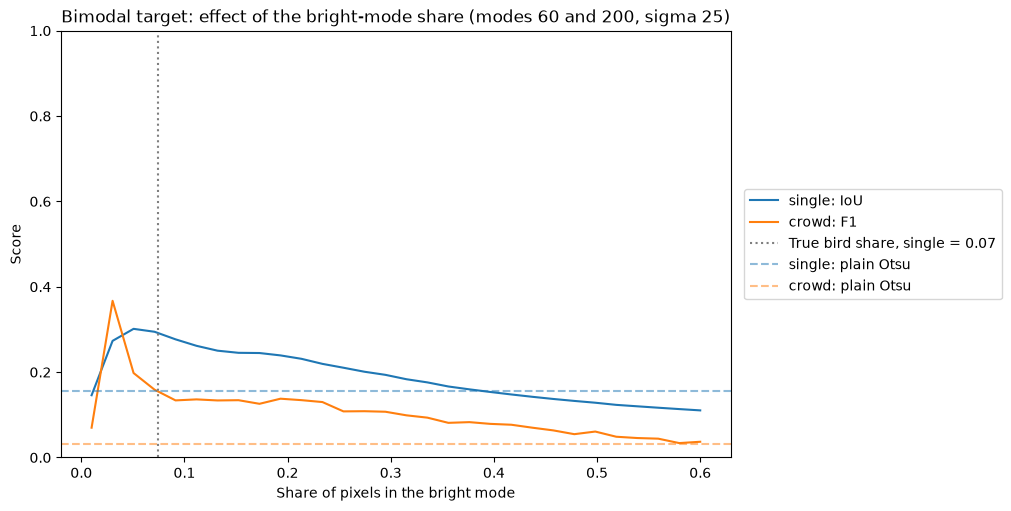

single: best share = 0.05, IoU = 0.301
crowd:  best share = 0.03, F1 = 0.367


In [21]:
SHARES = np.linspace(0.01, 0.6, 30)
iou_share = [iou(otsu_mask(match_histogram(albatross_single, bimodal_pdf(s)))[1], ref_single) for s in SHARES]
crowd_share = [crowd_scores(otsu_mask(match_histogram(albatross_crowd, bimodal_pdf(s)))[1])[2] for s in SHARES]

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(SHARES, iou_share, color=COLORS["single"], label="single: IoU")
ax.plot(SHARES, crowd_share, color=COLORS["crowd"], label="crowd: F1")
ax.axvline(BIRD_SHARE, color=COLORS["expected"], linestyle=":", label=f"True bird share, single = {BIRD_SHARE:.2f}")
ax.axhline(iou(mask0_s, ref_single), color=COLORS["single"], linestyle="--", alpha=0.5, label="single: plain Otsu")
ax.axhline(crowd_scores(mask0_c)[2], color=COLORS["crowd"], linestyle="--", alpha=0.5, label="crowd: plain Otsu")
ax.set_title("Bimodal target: effect of the bright-mode share (modes 60 and 200, sigma 25)")
ax.set_xlabel("Share of pixels in the bright mode")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()
print(f"single: best share = {SHARES[int(np.argmax(iou_share))]:.2f}, IoU = {max(iou_share):.3f}")
print(f"crowd:  best share = {SHARES[int(np.argmax(crowd_share))]:.2f}, F1 = {max(crowd_share):.3f}")

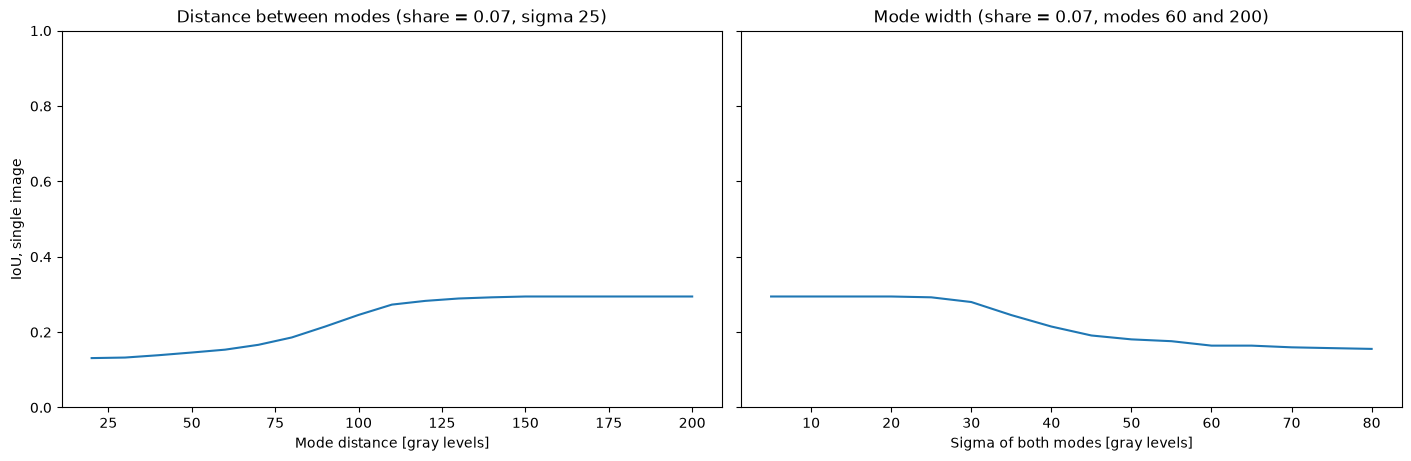

IoU range over separation: 0.131..0.295; over sigma: 0.156..0.295


In [22]:
SEPARATIONS = np.arange(20, 201, 10)   # distance between the mode centres
SIGMAS = np.arange(5, 81, 5)
MU_MID = 128
FIXED_SHARE = BIRD_SHARE

iou_sep = [iou(otsu_mask(match_histogram(albatross_single, bimodal_pdf(FIXED_SHARE, MU_MID - d / 2, MU_MID + d / 2)))[1], ref_single) for d in SEPARATIONS]
iou_sigma = [iou(otsu_mask(match_histogram(albatross_single, bimodal_pdf(FIXED_SHARE, sigma=s)))[1], ref_single) for s in SIGMAS]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True, sharey=True)
axes[0].plot(SEPARATIONS, iou_sep, color=COLORS["single"])
axes[0].set_title(f"Distance between modes (share = {FIXED_SHARE:.2f}, sigma 25)")
axes[0].set_xlabel("Mode distance [gray levels]")
axes[0].set_ylabel("IoU, single image")
axes[1].plot(SIGMAS, iou_sigma, color=COLORS["single"])
axes[1].set_title(f"Mode width (share = {FIXED_SHARE:.2f}, modes 60 and 200)")
axes[1].set_xlabel("Sigma of both modes [gray levels]")
for ax in axes:
    ax.set_ylim(0, 1)
plt.show()
print(f"IoU range over separation: {min(iou_sep):.3f}..{max(iou_sep):.3f}; over sigma: {min(iou_sigma):.3f}..{max(iou_sigma):.3f}")

Why is the score limited? Split the plain-Otsu and best-share masks into pixels inside and outside the reference polygon.

In [23]:
def inside_outside(mask, ref):
    inside = int(((mask > 0) & (ref > 0)).sum())
    outside = int(((mask > 0) & (ref == 0)).sum())
    return inside / int((ref > 0).sum()), outside


best_share_s = float(SHARES[int(np.argmax(iou_share))])
mask_best_s = otsu_mask(match_histogram(albatross_single, bimodal_pdf(best_share_s)))[1]
for label, m in [("plain Otsu", mask0_s), (f"matched, share {best_share_s:.2f}", mask_best_s)]:
    cover, outside = inside_outside(m, ref_single)
    print(f"{label:25s} polygon covered: {cover:.1%}, mask pixels outside polygon: {outside}")

plain Otsu                polygon covered: 84.9%, mask pixels outside polygon: 130403
matched, share 0.05       polygon covered: 40.3%, mask pixels outside polygon: 9831


A global gray-level mapping cannot remove thin bright grass blades. Test a smoothing step before the transformation (median kernel, in pixels).

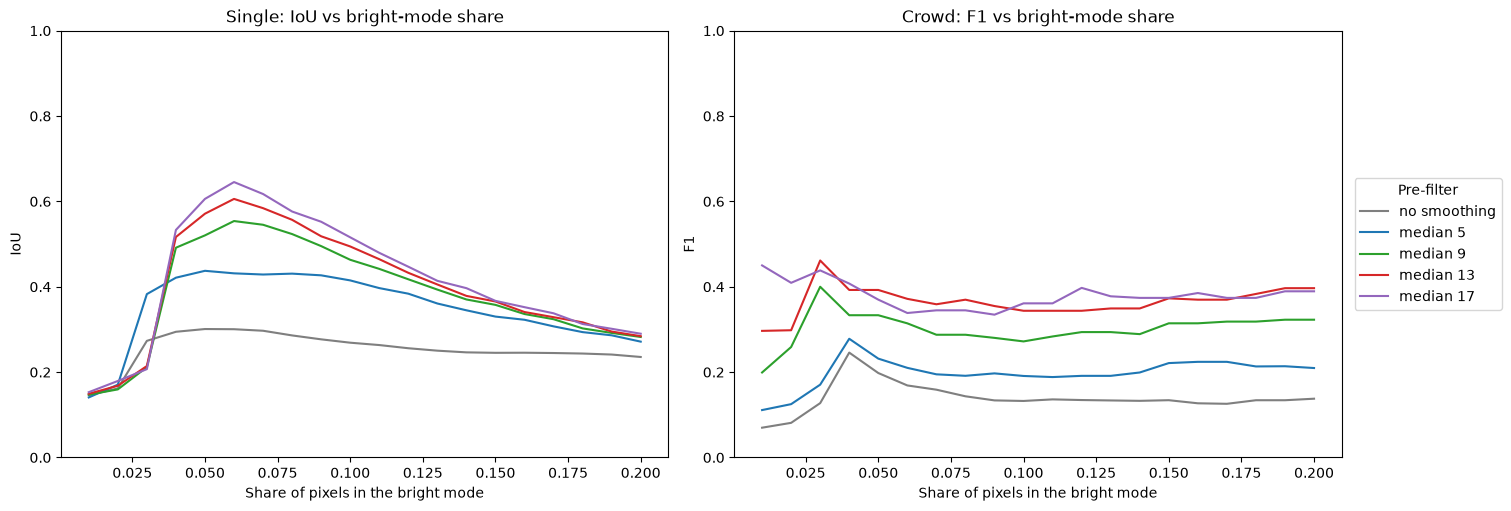

median  1: single best share 0.05 IoU 0.301 | crowd best share 0.04 F1 0.246
median  5: single best share 0.05 IoU 0.437 | crowd best share 0.04 F1 0.278
median  9: single best share 0.06 IoU 0.554 | crowd best share 0.03 F1 0.400
median 13: single best share 0.06 IoU 0.606 | crowd best share 0.03 F1 0.462
median 17: single best share 0.06 IoU 0.645 | crowd best share 0.01 F1 0.450


In [24]:
PRE_KERNELS = (1, 5, 9, 13, 17)
SHARES_FINE = np.linspace(0.01, 0.2, 20)
PRE_COLORS = dict(zip(PRE_KERNELS, ["tab:gray", "tab:blue", "tab:green", "tab:red", "tab:purple"]))


def prefilter(img, k):
    return img if k == 1 else cv2.medianBlur(img, k)


fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
pre_best = {}
for k in PRE_KERNELS:
    s_scores = [iou(otsu_mask(match_histogram(prefilter(albatross_single, k), bimodal_pdf(s)))[1], ref_single) for s in SHARES_FINE]
    c_scores = [crowd_scores(otsu_mask(match_histogram(prefilter(albatross_crowd, k), bimodal_pdf(s)))[1])[2] for s in SHARES_FINE]
    axes[0].plot(SHARES_FINE, s_scores, color=PRE_COLORS[k], label=f"median {k}" if k > 1 else "no smoothing")
    axes[1].plot(SHARES_FINE, c_scores, color=PRE_COLORS[k], label=f"median {k}" if k > 1 else "no smoothing")
    pre_best[k] = (SHARES_FINE[int(np.argmax(s_scores))], max(s_scores), SHARES_FINE[int(np.argmax(c_scores))], max(c_scores))
axes[0].set_title("Single: IoU vs bright-mode share")
axes[1].set_title("Crowd: F1 vs bright-mode share")
for ax, ylab in zip(axes, ["IoU", "F1"]):
    ax.set_xlabel("Share of pixels in the bright mode")
    ax.set_ylabel(ylab)
    ax.set_ylim(0, 1)
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Pre-filter")
plt.show()
for k, (ss, si, cs, cf) in pre_best.items():
    print(f"median {k:2d}: single best share {ss:.2f} IoU {si:.3f} | crowd best share {cs:.2f} F1 {cf:.3f}")

Final result: best pre-filter kernel and bright-mode share per image, chosen from the study above.

single: median 17, share 0.06 | crowd: median 13, share 0.03


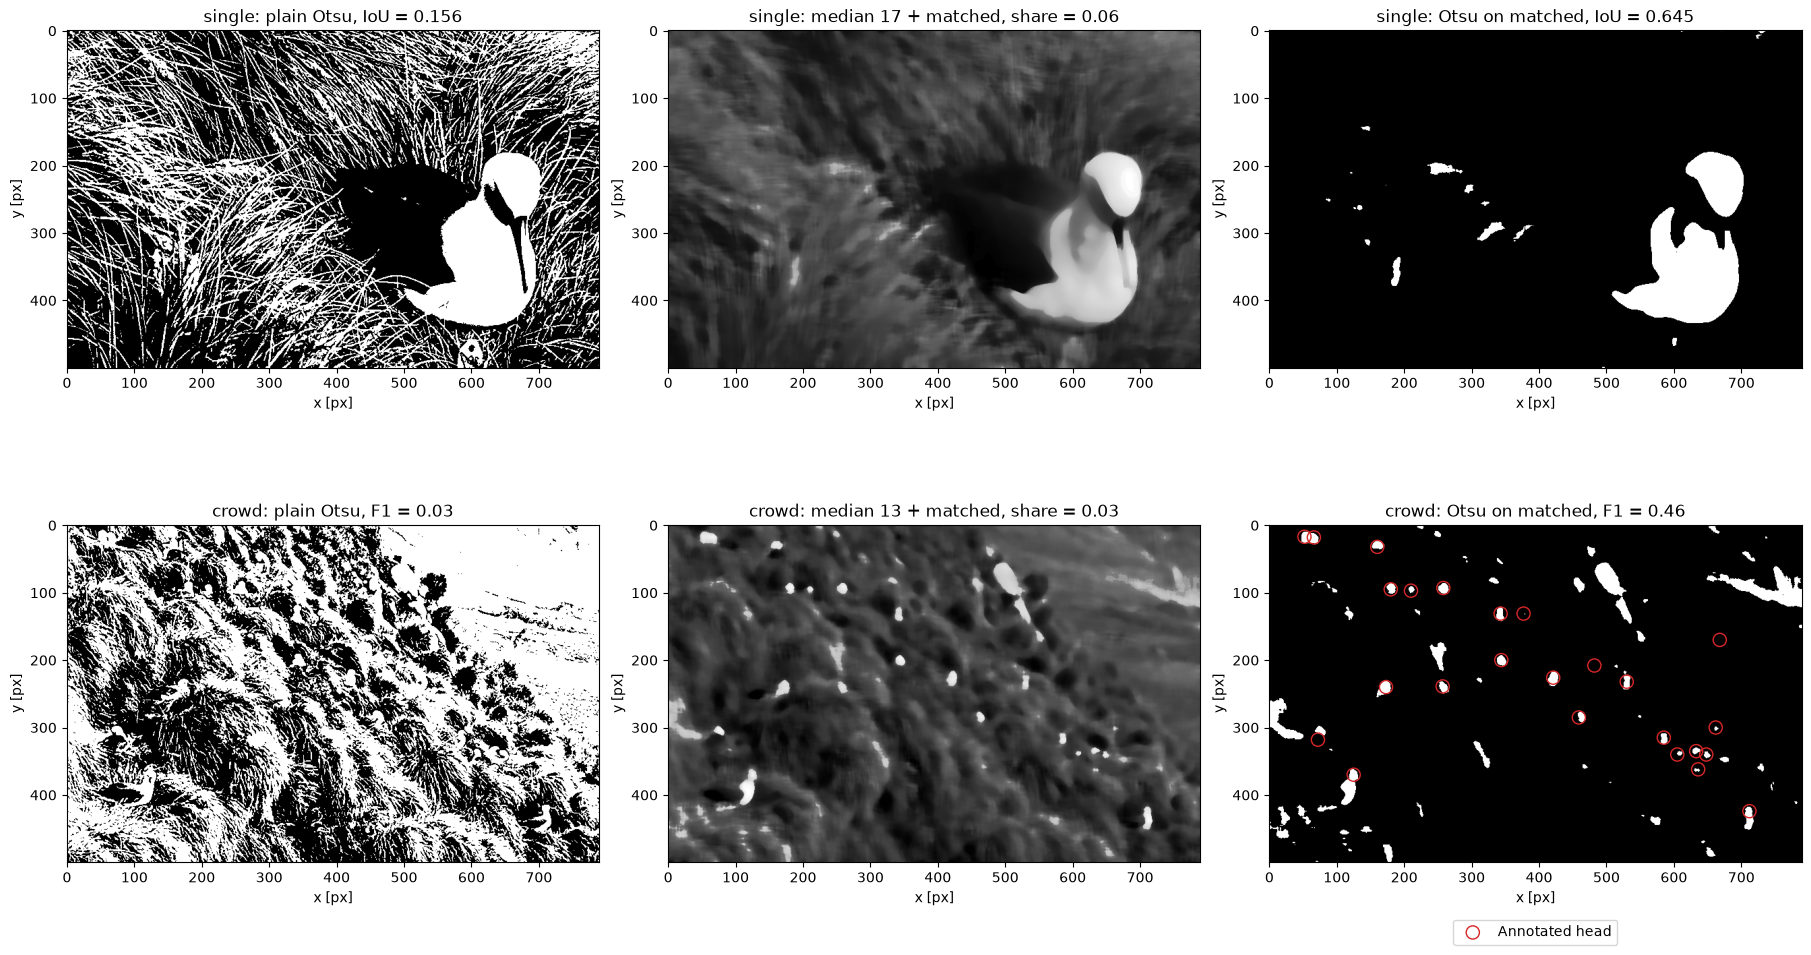

crowd: recall = 0.84, precision = 0.32, F1 = 0.46, components = 66


In [25]:
KERNEL_SINGLE = max(pre_best, key=lambda k: pre_best[k][1])
KERNEL_CROWD = max(pre_best, key=lambda k: pre_best[k][3])
BEST_SHARE_SINGLE = float(pre_best[KERNEL_SINGLE][0])
BEST_SHARE_CROWD = float(pre_best[KERNEL_CROWD][2])
print(f"single: median {KERNEL_SINGLE}, share {BEST_SHARE_SINGLE:.2f} | crowd: median {KERNEL_CROWD}, share {BEST_SHARE_CROWD:.2f}")

out_s = match_histogram(prefilter(albatross_single, KERNEL_SINGLE), bimodal_pdf(BEST_SHARE_SINGLE))
out_c = match_histogram(prefilter(albatross_crowd, KERNEL_CROWD), bimodal_pdf(BEST_SHARE_CROWD))
t_s, mask_s = otsu_mask(out_s)
t_c, mask_c = otsu_mask(out_c)

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
show_image(axes[0, 0], mask0_s, f"single: plain Otsu, IoU = {iou(mask0_s, ref_single):.3f}")
show_image(axes[0, 1], out_s, f"single: median {KERNEL_SINGLE} + matched, share = {BEST_SHARE_SINGLE:.2f}")
show_image(axes[0, 2], mask_s, f"single: Otsu on matched, IoU = {iou(mask_s, ref_single):.3f}")
show_image(axes[1, 0], mask0_c, f"crowd: plain Otsu, F1 = {crowd_scores(mask0_c)[2]:.2f}")
show_image(axes[1, 1], out_c, f"crowd: median {KERNEL_CROWD} + matched, share = {BEST_SHARE_CROWD:.2f}")
show_image(axes[1, 2], mask_c, f"crowd: Otsu on matched, F1 = {crowd_scores(mask_c)[2]:.2f}")
axes[1, 2].scatter(*CROWD_POINTS.T, s=90, facecolors="none", edgecolors="tab:red", label="Annotated head")
axes[1, 2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()
r, p, f, n = crowd_scores(mask_c)
print(f"crowd: recall = {r:.2f}, precision = {p:.2f}, F1 = {f:.2f}, components = {n}")

Conclusions 4:
- Plain Otsu: single IoU 0.156, crowd precision 0.02 (249 components). Grass and rocks are as bright as the birds.
- Uniform and Gaussian targets give IoU 0.128 (Otsu T = 128); a bimodal target with a small bright mode gives IoU 0.30 (no smoothing).
- Most important target parameter: the share of the bright mode. The IoU peaks at 0.05-0.06, close to the true bird share 0.074, and falls on both sides. Mode distance and width matter only when the modes overlap (distance below about 110, sigma above about 30).
- The matching is a monotone gray-level mapping, so it only moves the effective threshold; it cannot remove thin bright grass blades. Median smoothing before the matching helps most: IoU 0.30 to 0.65 for the single bird.
- Crowd: best F1 0.46 (recall 0.84, precision 0.32). False positives are bright grass patches and rocks; small birds are lost with larger median kernels.
- Reference annotations were drawn by hand, so IoU and F1 are approximate; unannotated tiny birds count as false positives.